# REFIT walkthrough

We estimate washing-machine power from one-minute whole-home readings using a simple activity classifier and an active-power regressor. On House 3, minute F1 is 42.84% and cycle F1 is 52.09%, with 9.0-minute median matched start error. Stage 2 active-minute MAE is 347.23 W versus 462.28 W for the plain classifier, while overall MAE is 48.49 versus 32.13 W. Both named splits and six-house LOHO show where results transfer and where they fail.

| Evaluation | Model | MAE W | Active MAE W | F1 % | Energy error % |
| --- | --- | --- | --- | --- | --- |
| House 3 test | always_off | 28.649 | 505.480 | 0.000 | 100.000 |
| 6-house mean | always_off | 26.226 | 527.546 | 0.000 | 100.000 |
| House 3 test | usage_profile | 48.610 | 470.021 | 16.705 | 15.863 |
| 6-house mean | usage_profile | 48.093 | 500.645 | 11.481 | 61.792 |
| House 3 test | two_stage_hgb | 48.487 | 347.226 | 42.836 | 53.030 |
| 6-house mean | two_stage_hgb | 46.667 | 356.673 | 36.995 | 78.569 |

Overlapping high-power appliances cause false positives; 94.34% of House 3 evaluated minutes are below the 20 W activity threshold. House 3 overall MAE is 48.49 W versus always-off 28.65 W; total-energy error is 53.03% versus hourly-profile 15.86%. The suitable use is evaluated cycle timing and opt-in feedback, not appliance billing.



In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display,Image
R=Path('reports')
pd.set_option('display.max_columns',None)

## Raw audit
Stable keep-last duplicates, invalid/outlier masking, one-minute means, and interpolation of complete gaps no longer than two minutes.

In [2]:
display(pd.DataFrame(list(json.loads((R/'raw_house1/audit.json').read_text()).items()),columns=['Finding','Value']))

,Finding,Value
0,files,"[RAW_House1_Part1.csv, RAW_House1_Part2.csv]"
1,source_rows,8518763
2,invalid_time_text,0
3,invalid_unix,0
4,duplicate_unix_rows,1211048
5,backward_steps,2
6,time_minus_unix_seconds_counts,"{'0.0': 4365920, '1.0': 4152843}"
7,text_unix_discrepancy_rows,4152843
8,negative_cells,0
9,nonfinite_cells,5284083


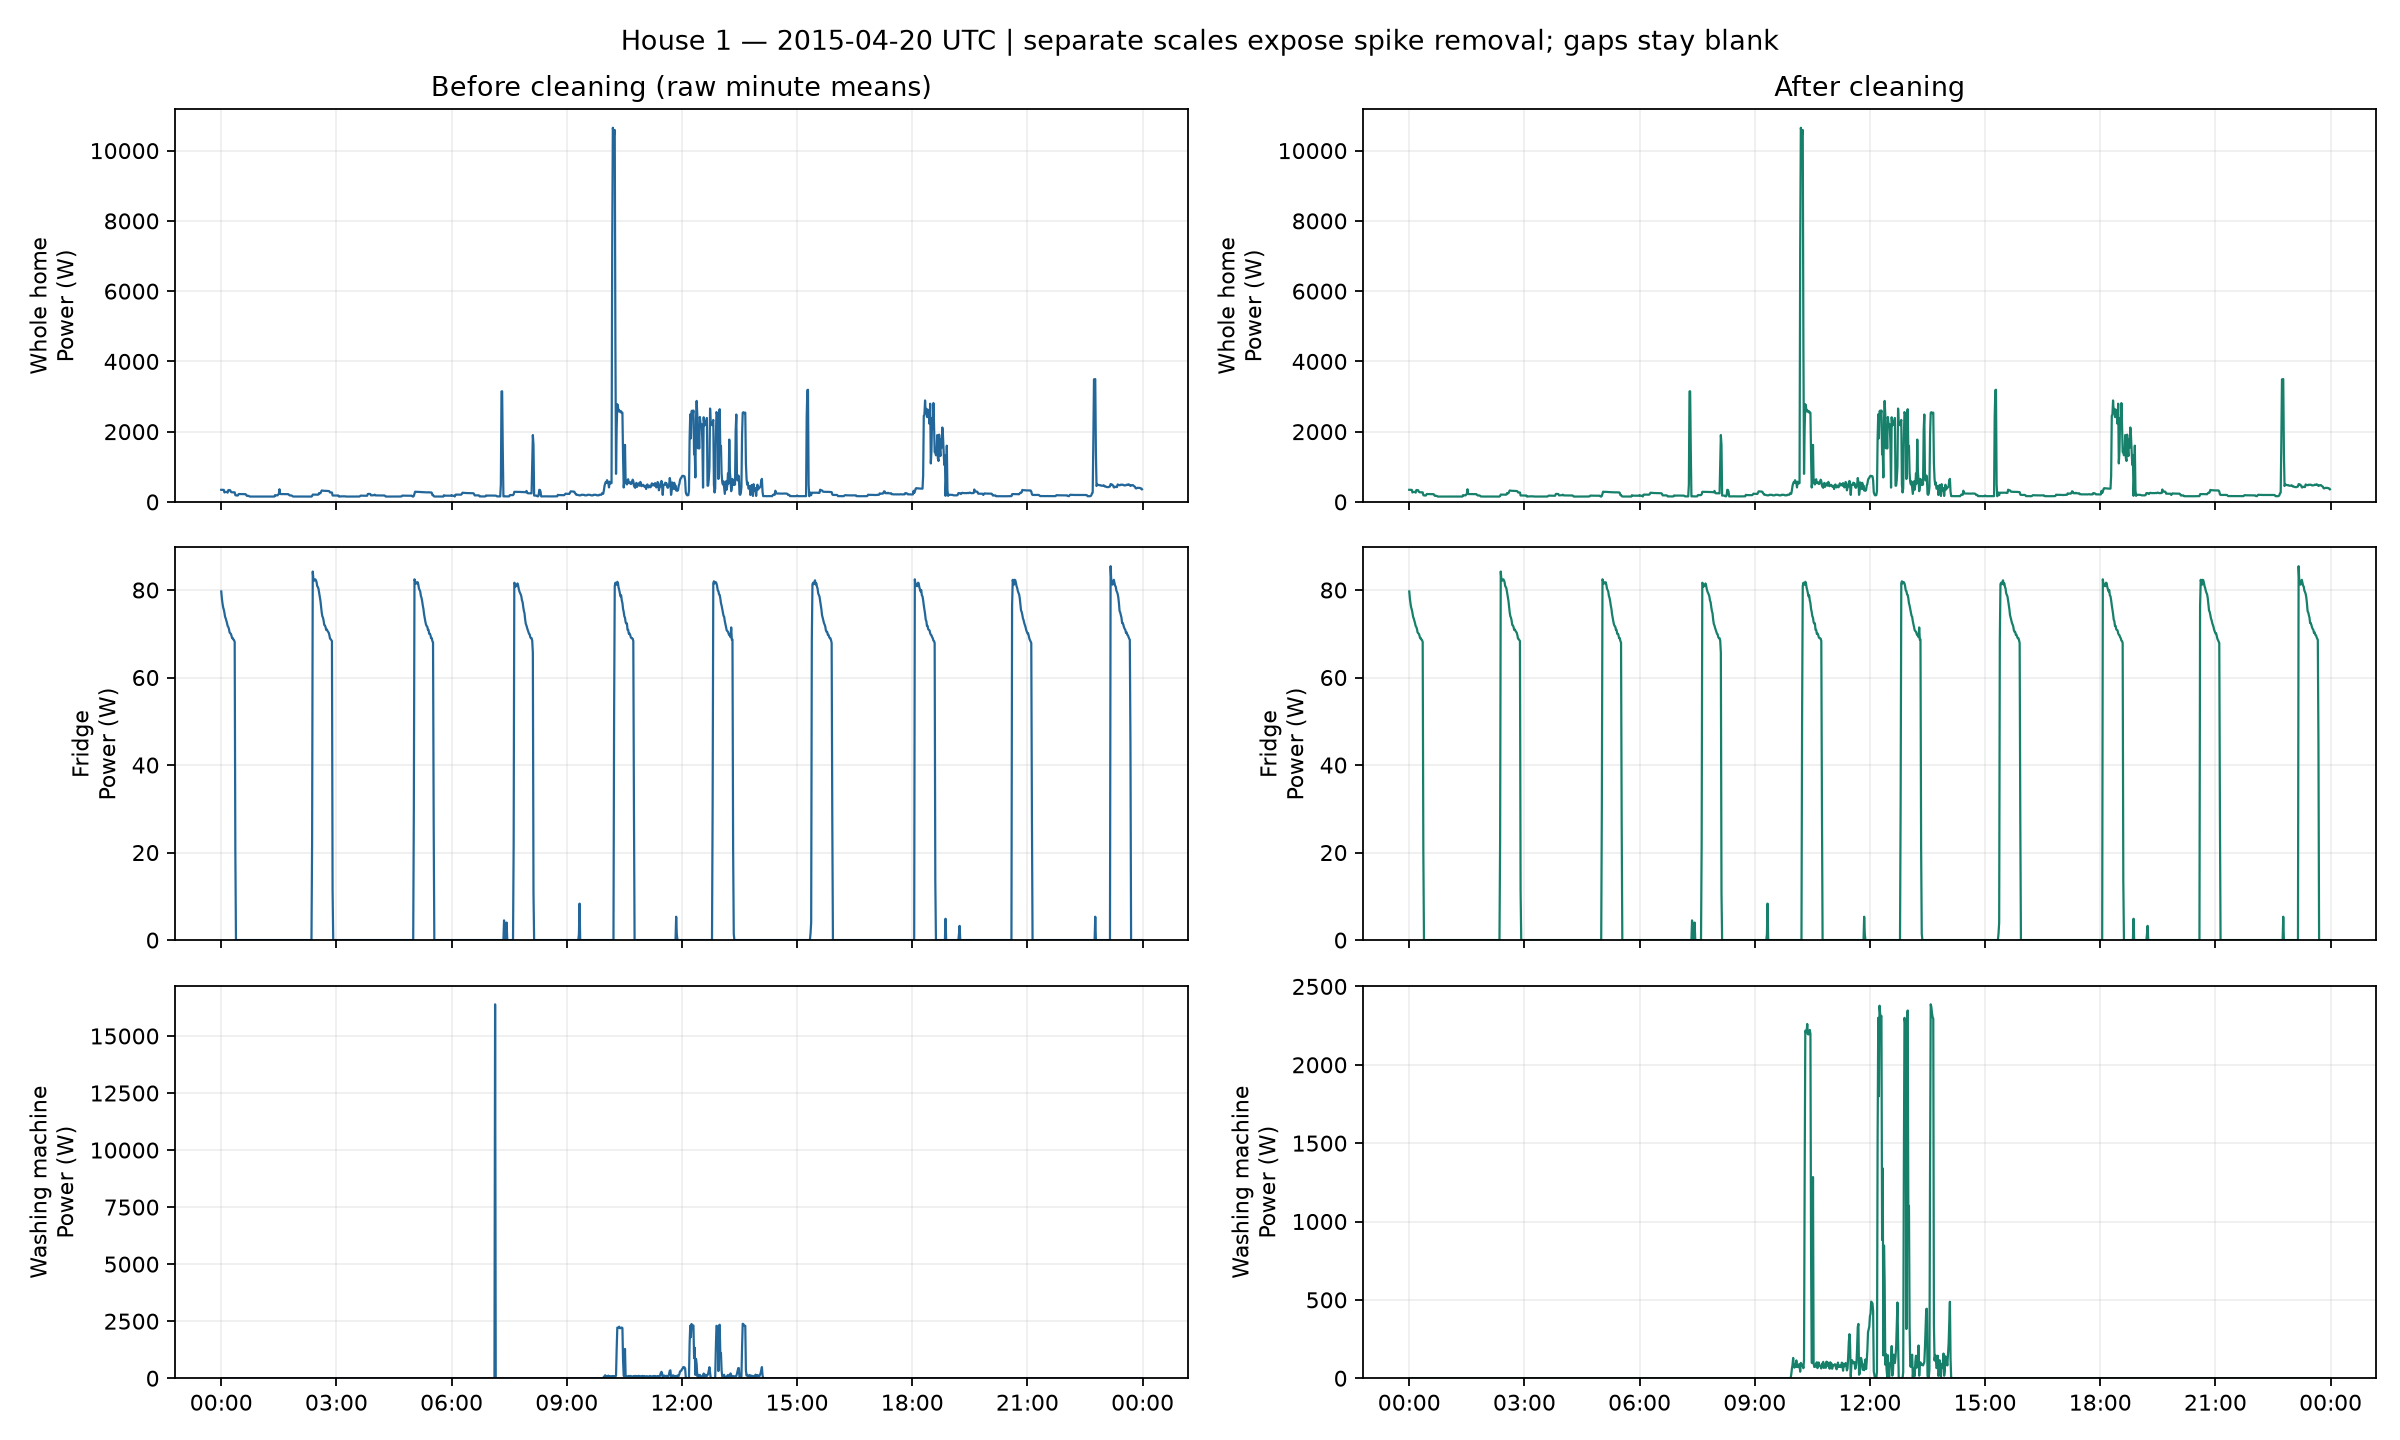

In [3]:
display(Image(filename=str(R/'raw_house1/before_after.png')))

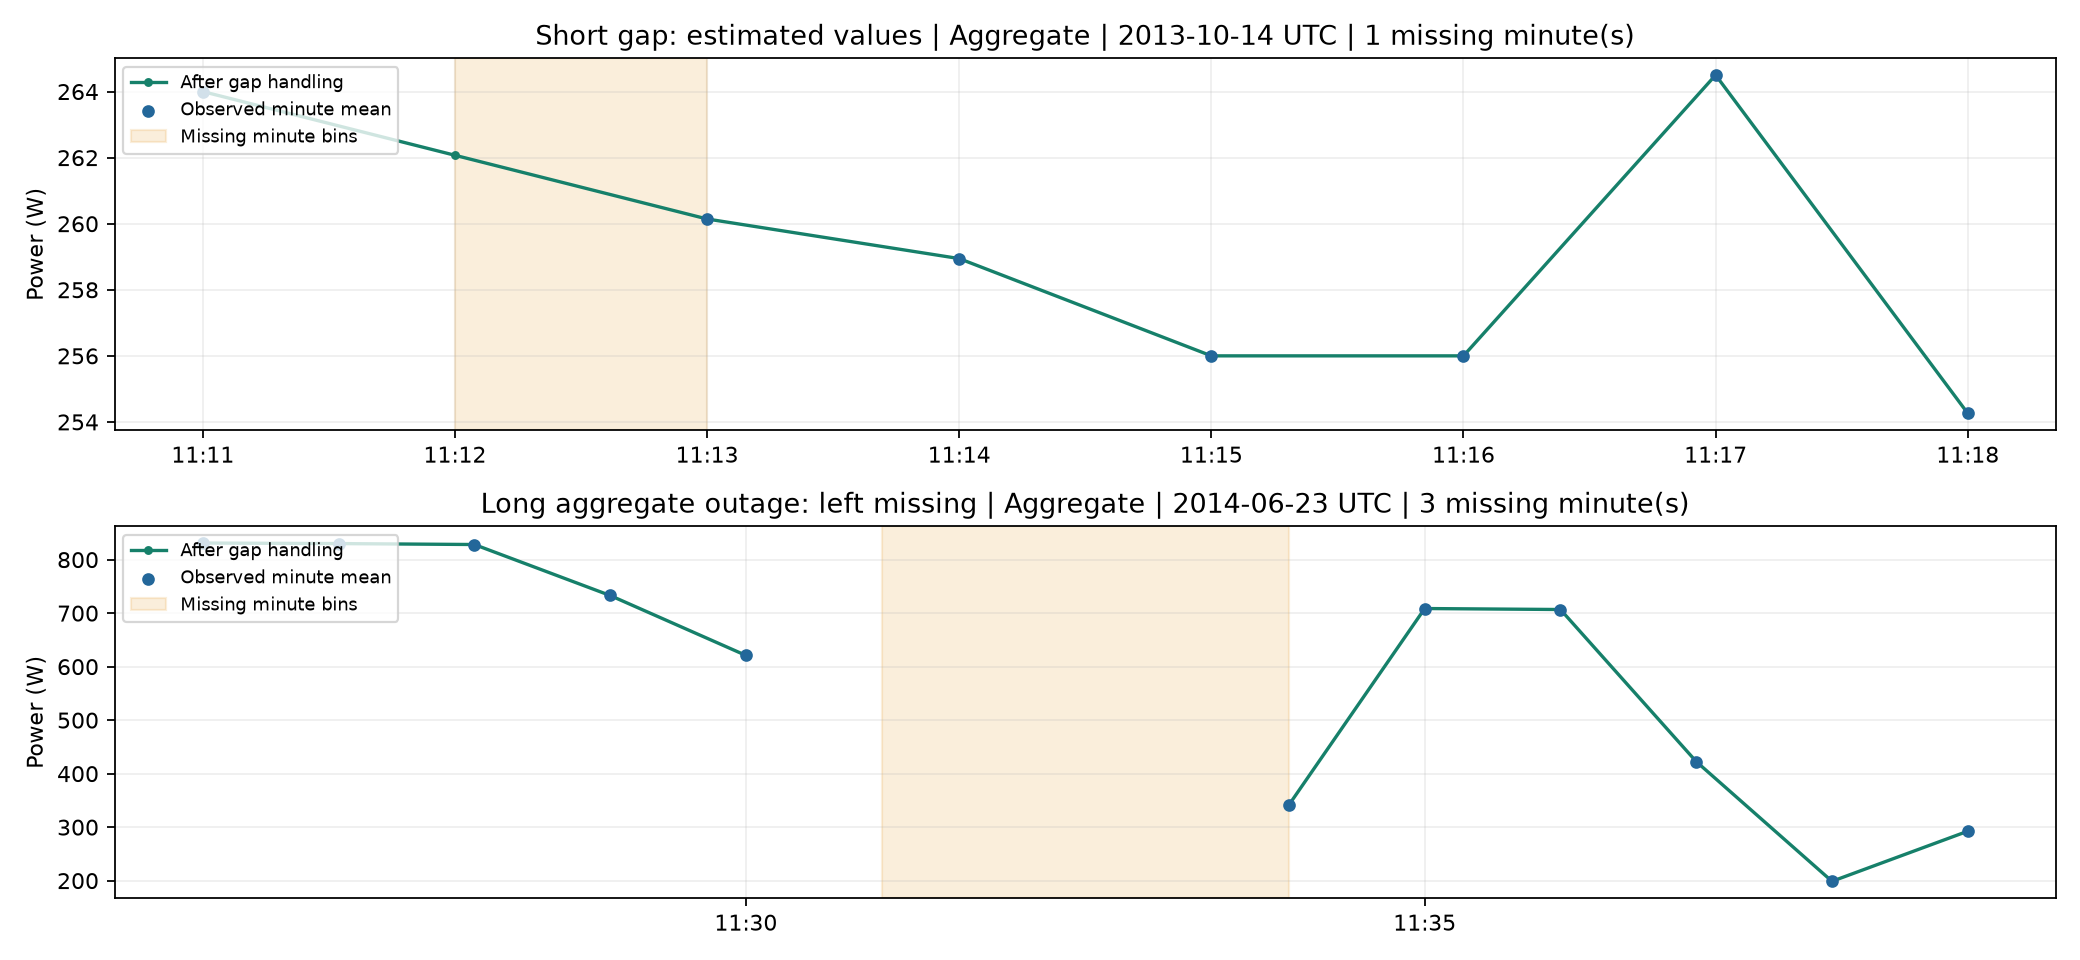

In [4]:
display(Image(filename=str(R/'raw_house1/gap_examples.png')))

## Washing-machine EDA
Active >=20 W, observed pauses <=15 minutes, sessions >=20 minutes AND >=0.10 kWh. Missing minutes are not off time.

In [5]:
display(pd.read_csv(R/'eda/eda_summary_table.csv'))

,house,wm_channel,start_date,end_date,calendar_span_days,calendar_minutes,usable_minutes,missing_pct,missing_nan_minutes,insufficient_minutes,off_pct,detected_cycles,cycles_per_observed_week,duration_minutes_median,duration_minutes_mean,duration_minutes_p25,duration_minutes_p75,peak_minute_mean_w_median,peak_minute_mean_w_mean,peak_minute_mean_w_p25,peak_minute_mean_w_p75,energy_kwh_median,energy_kwh_mean,energy_kwh_p25,energy_kwh_p75
0,1,Appliance5,2013-10-09 13:06:17,2015-07-10 11:56:32,638.952083,920091,799631,12.642010,116318,4142,98.113505,369,4.651546,33.0,44.544715,32.0,38.0,2327.750000,2311.718508,2285.333333,2366.900000,0.322422,0.381232,0.261151,0.376509
1,2,Appliance2,2013-09-17 22:08:11,2015-05-28 08:05:43,617.415278,889078,664711,24.622587,218914,5453,95.284116,314,4.761648,97.0,103.522293,88.0,106.0,2090.533333,2071.092264,2068.694444,2115.833333,0.626334,0.631278,0.491046,0.704636
2,3,Appliance6,2013-09-25 19:21:09,2015-06-02 10:55:42,614.649306,885095,780206,11.376519,100693,4196,94.326755,631,8.152308,66.0,68.866878,62.0,70.0,1927.300000,1925.027629,1886.750000,1966.212500,0.554732,0.579658,0.467286,0.656129
3,7,Appliance5,2013-11-01 22:01:18,2015-07-08 02:10:54,613.173611,882970,765973,12.575965,111042,5955,91.585604,834,10.975217,61.0,76.796163,57.0,106.0,2082.477778,2072.375910,2054.361111,2108.396429,0.546432,0.574442,0.450037,0.648737
4,8,Appliance4,2013-11-01 22:13:18,2015-05-10 23:36:10,555.058333,799284,710987,10.267064,82063,6234,96.653103,369,5.231488,59.0,64.493225,50.0,76.0,2337.200000,2320.071748,2291.444444,2374.500000,0.786390,0.936252,0.617242,1.261918
5,10,Appliance5,2013-11-20 11:31:18,2015-06-30 11:07:07,586.984028,845257,740301,11.200262,94671,10285,91.201552,584,7.951793,120.0,112.583904,118.0,122.0,2056.000000,2001.209302,1984.722222,2097.500000,0.709862,0.674460,0.620450,0.750011


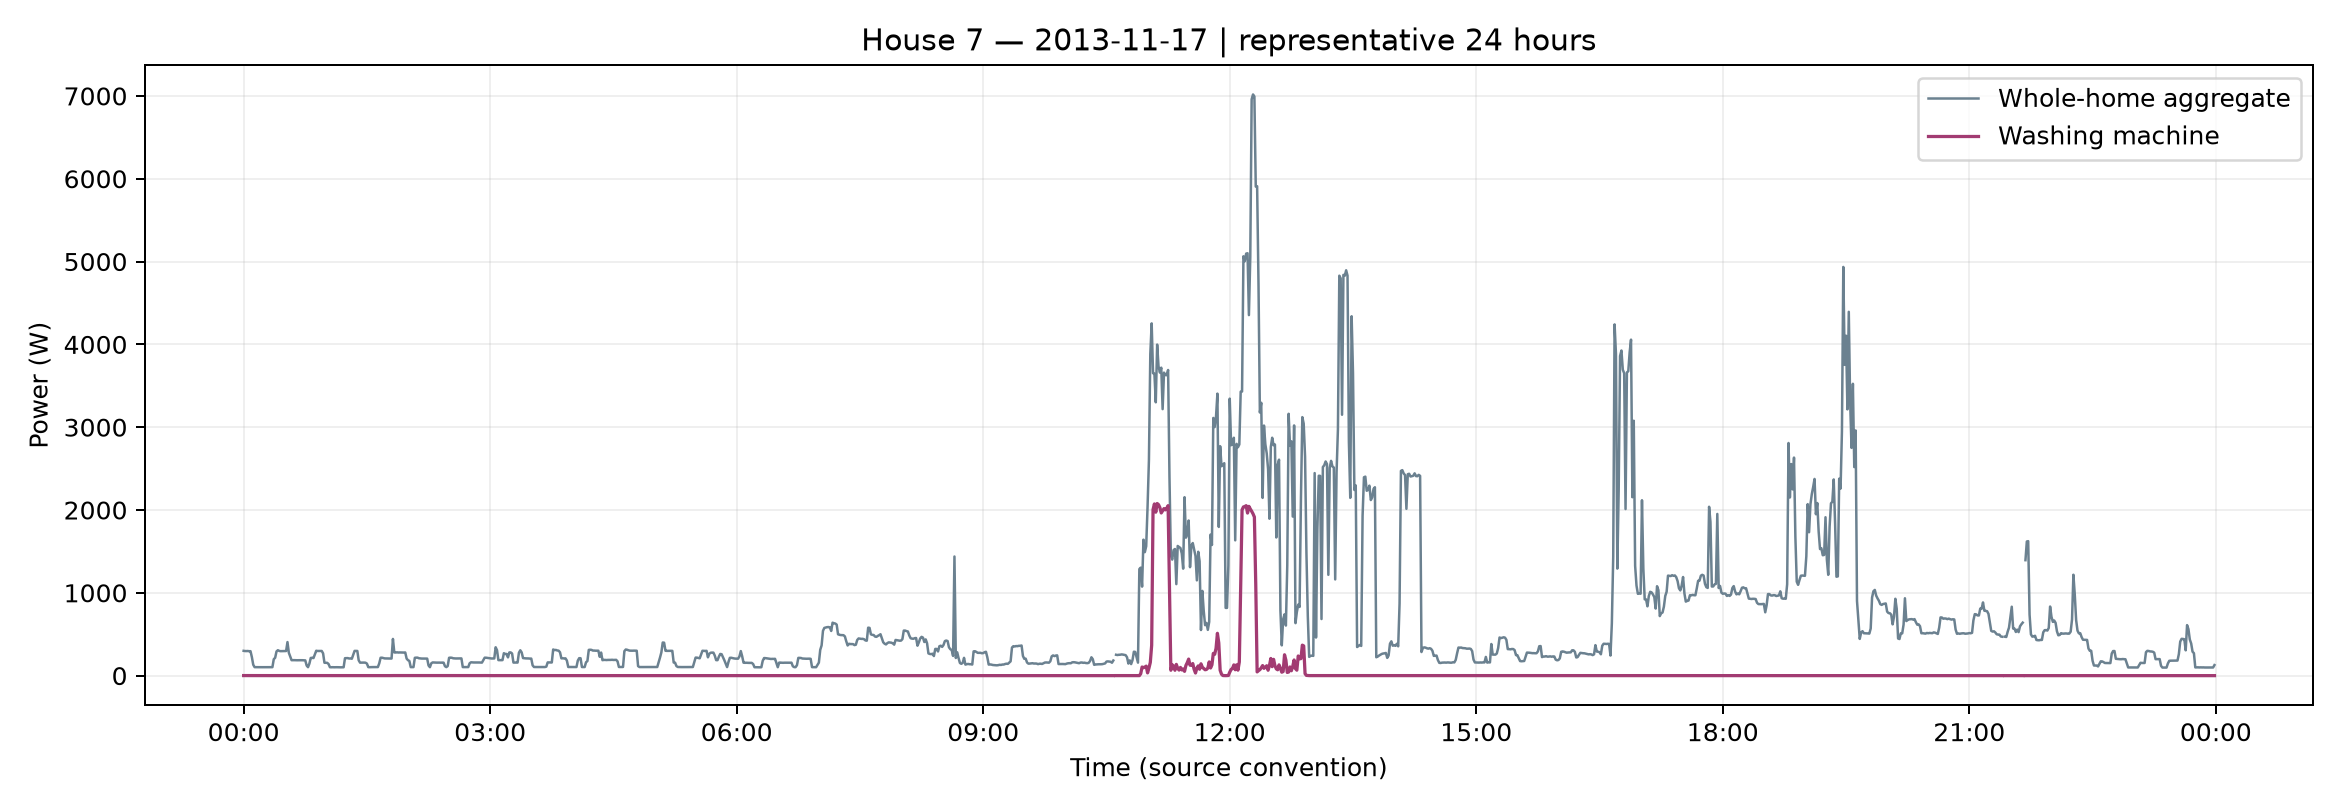

In [6]:
display(Image(filename=str(R/'eda/figures/24h_aggregate_and_wm_trace.png')))

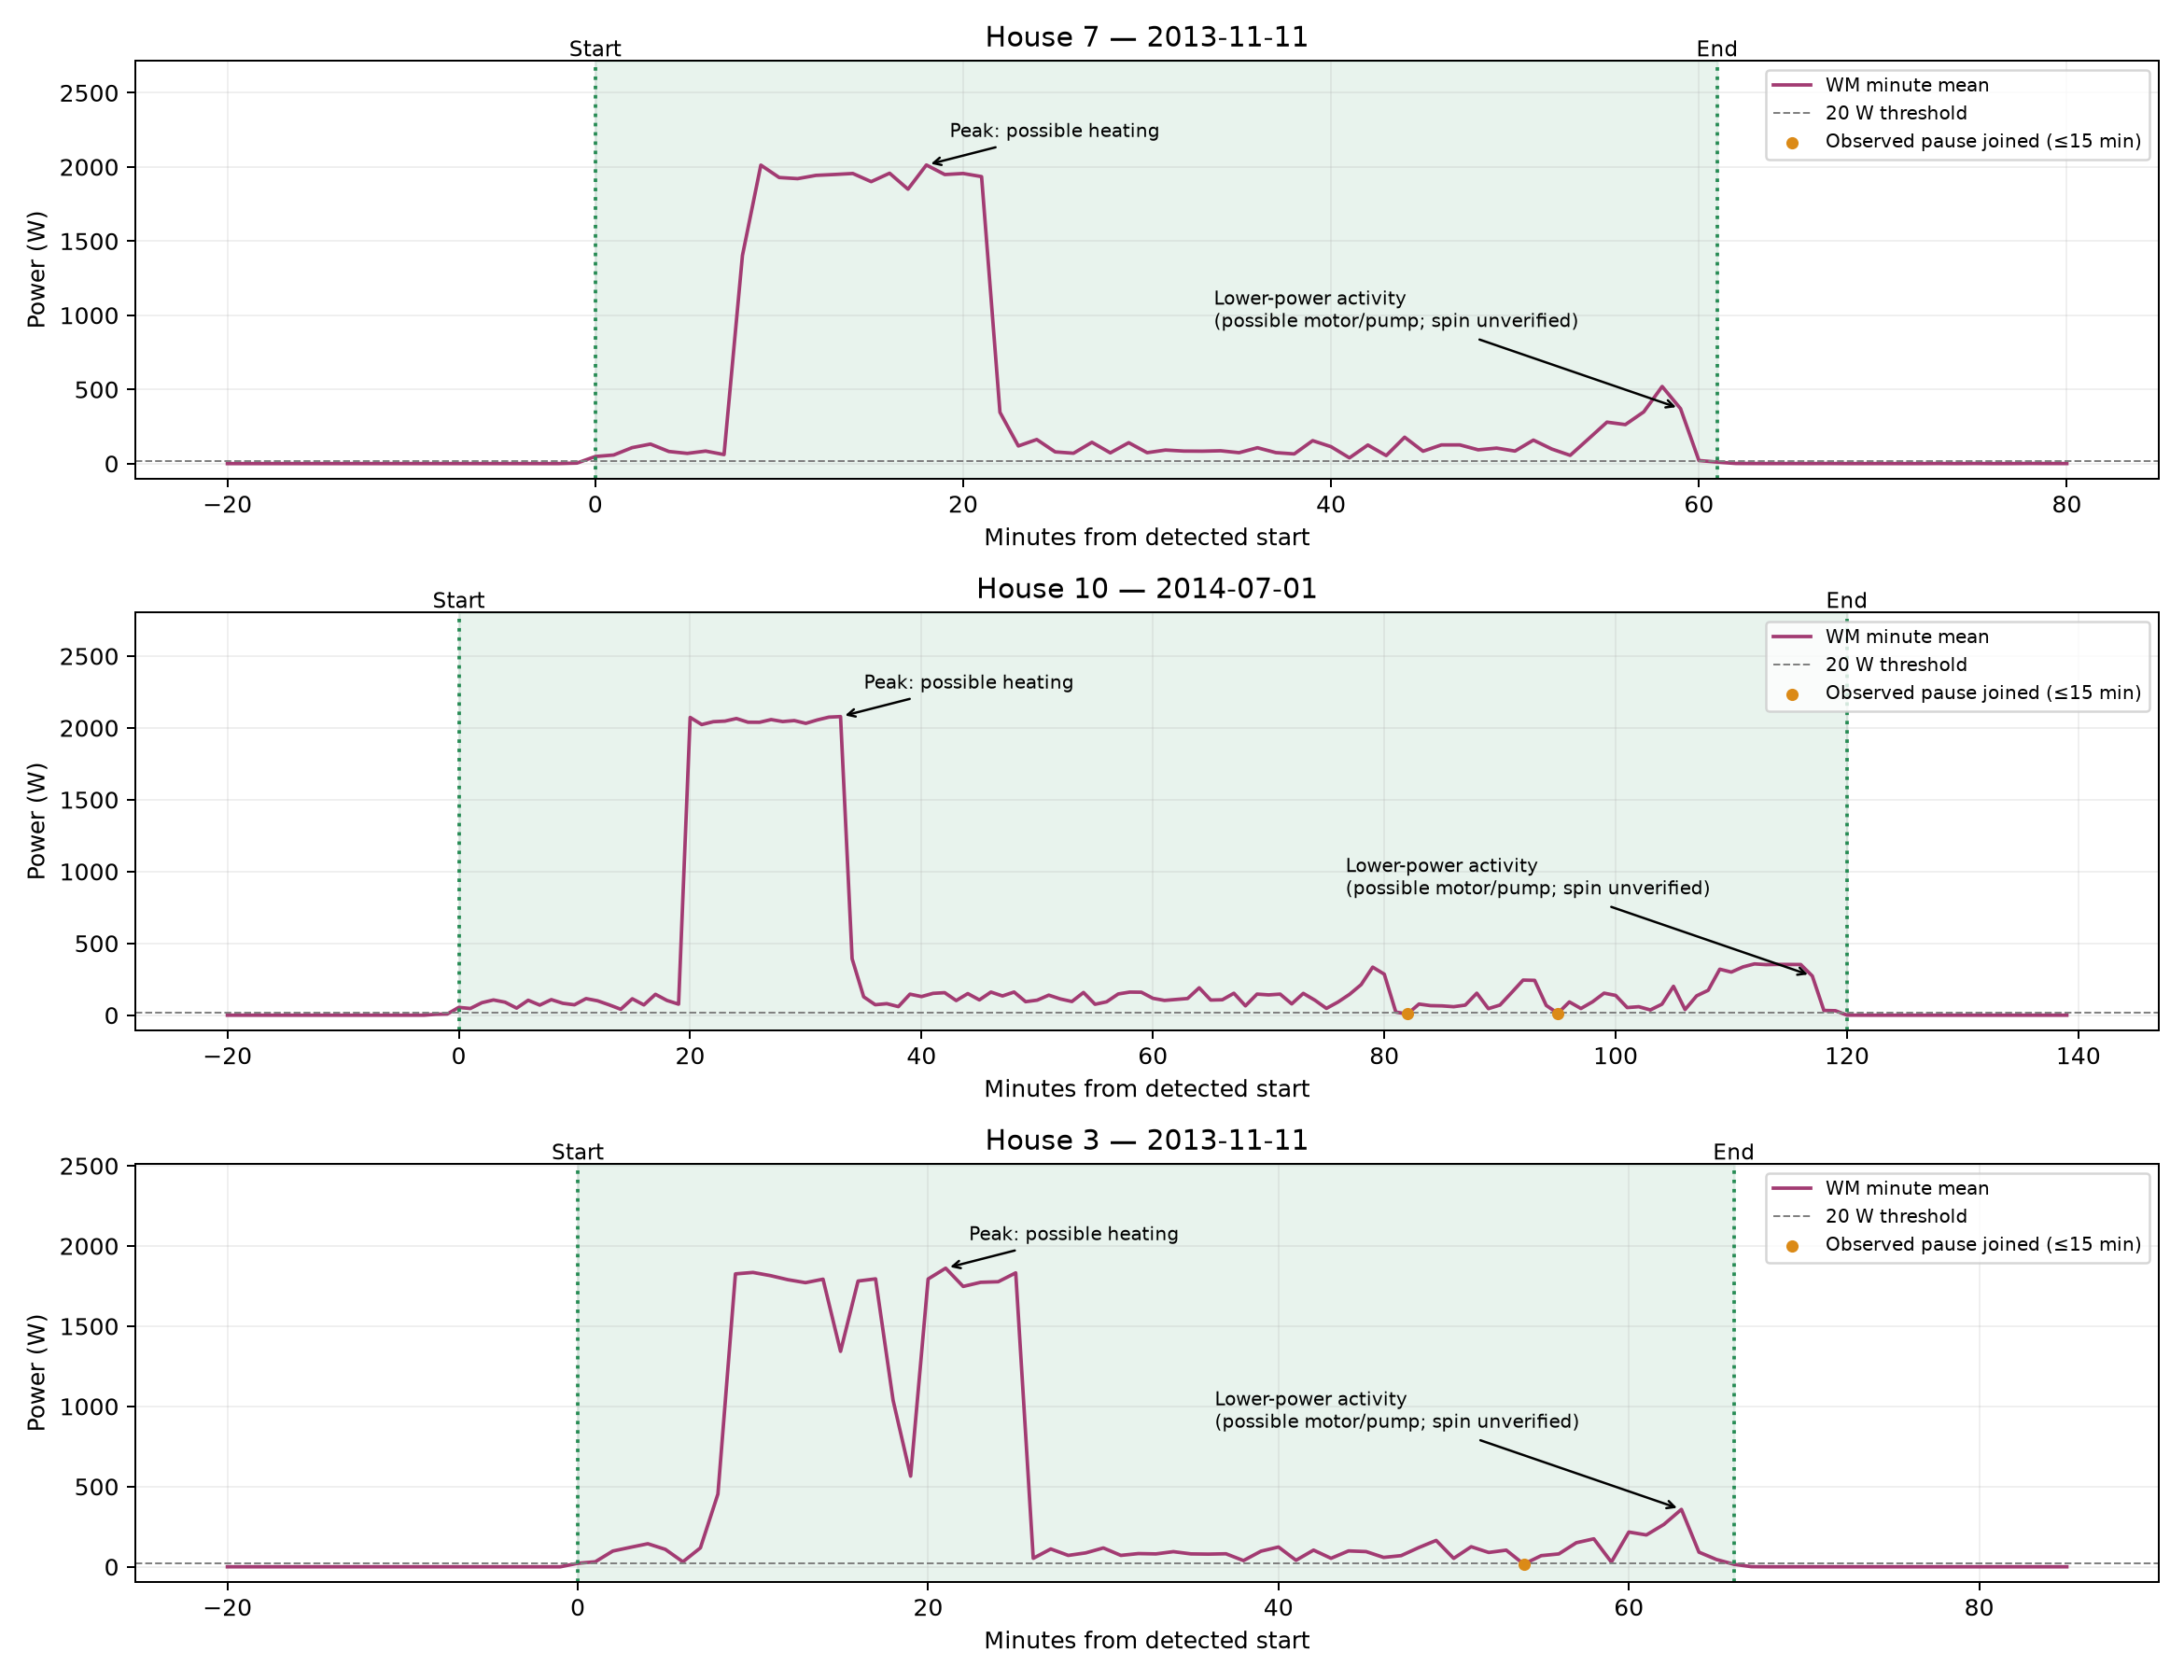

In [7]:
display(Image(filename=str(R/'eda/figures/detected_wm_cycles_zoom.png')))

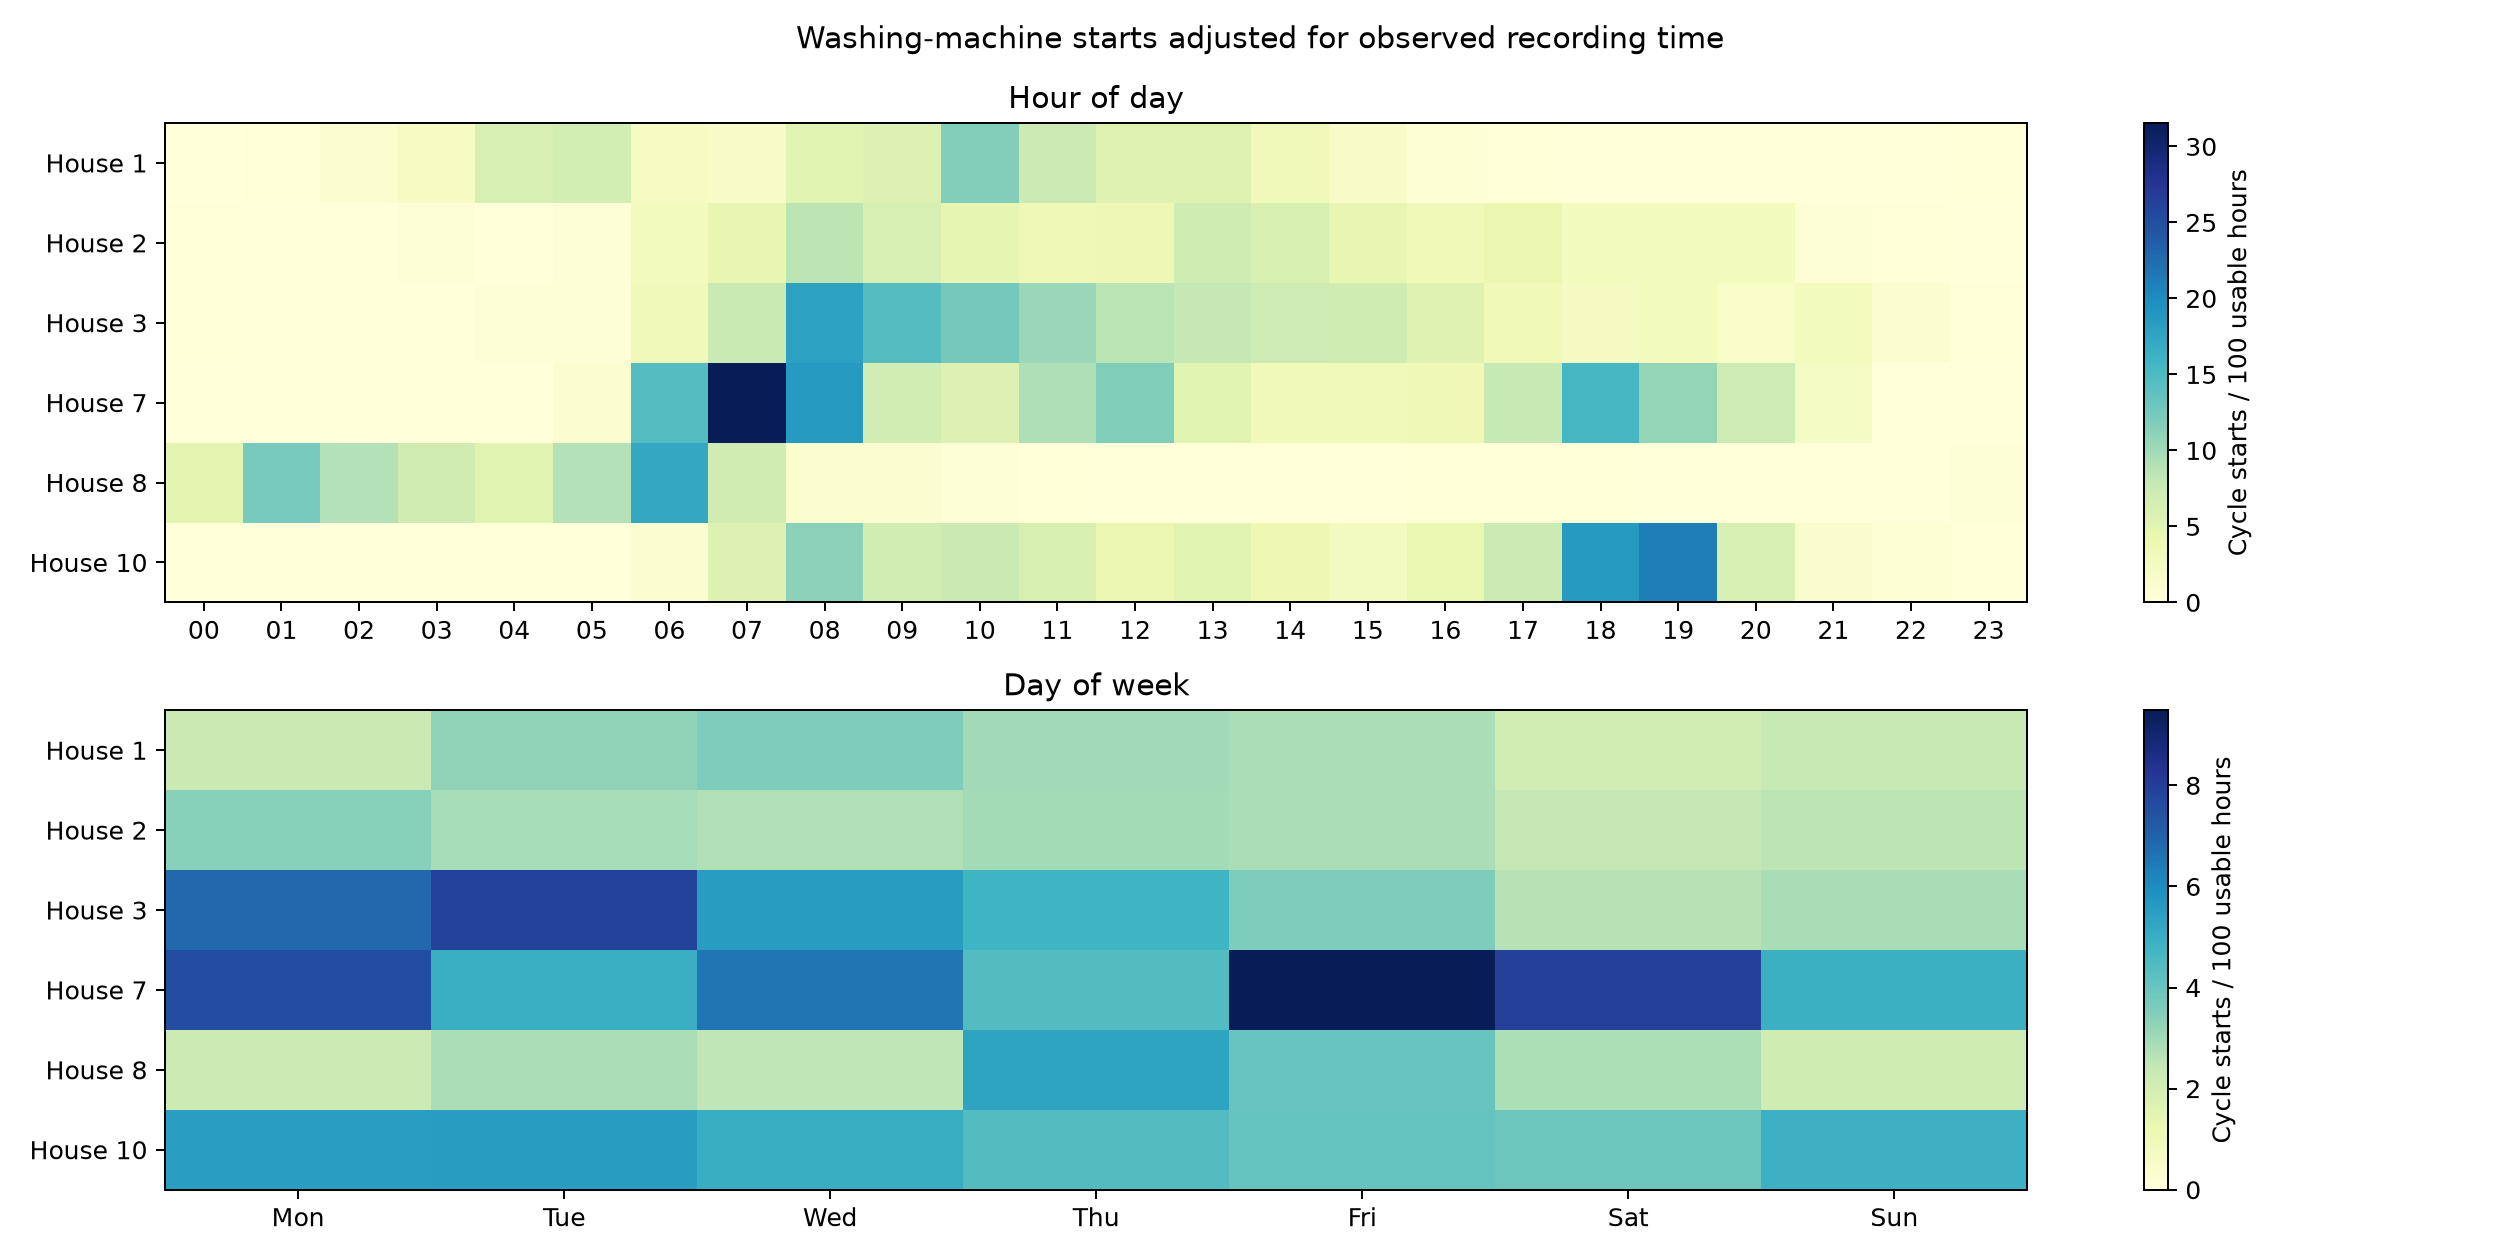

In [8]:
display(Image(filename=str(R/'eda/figures/usage_patterns_hour_weekday.png')))

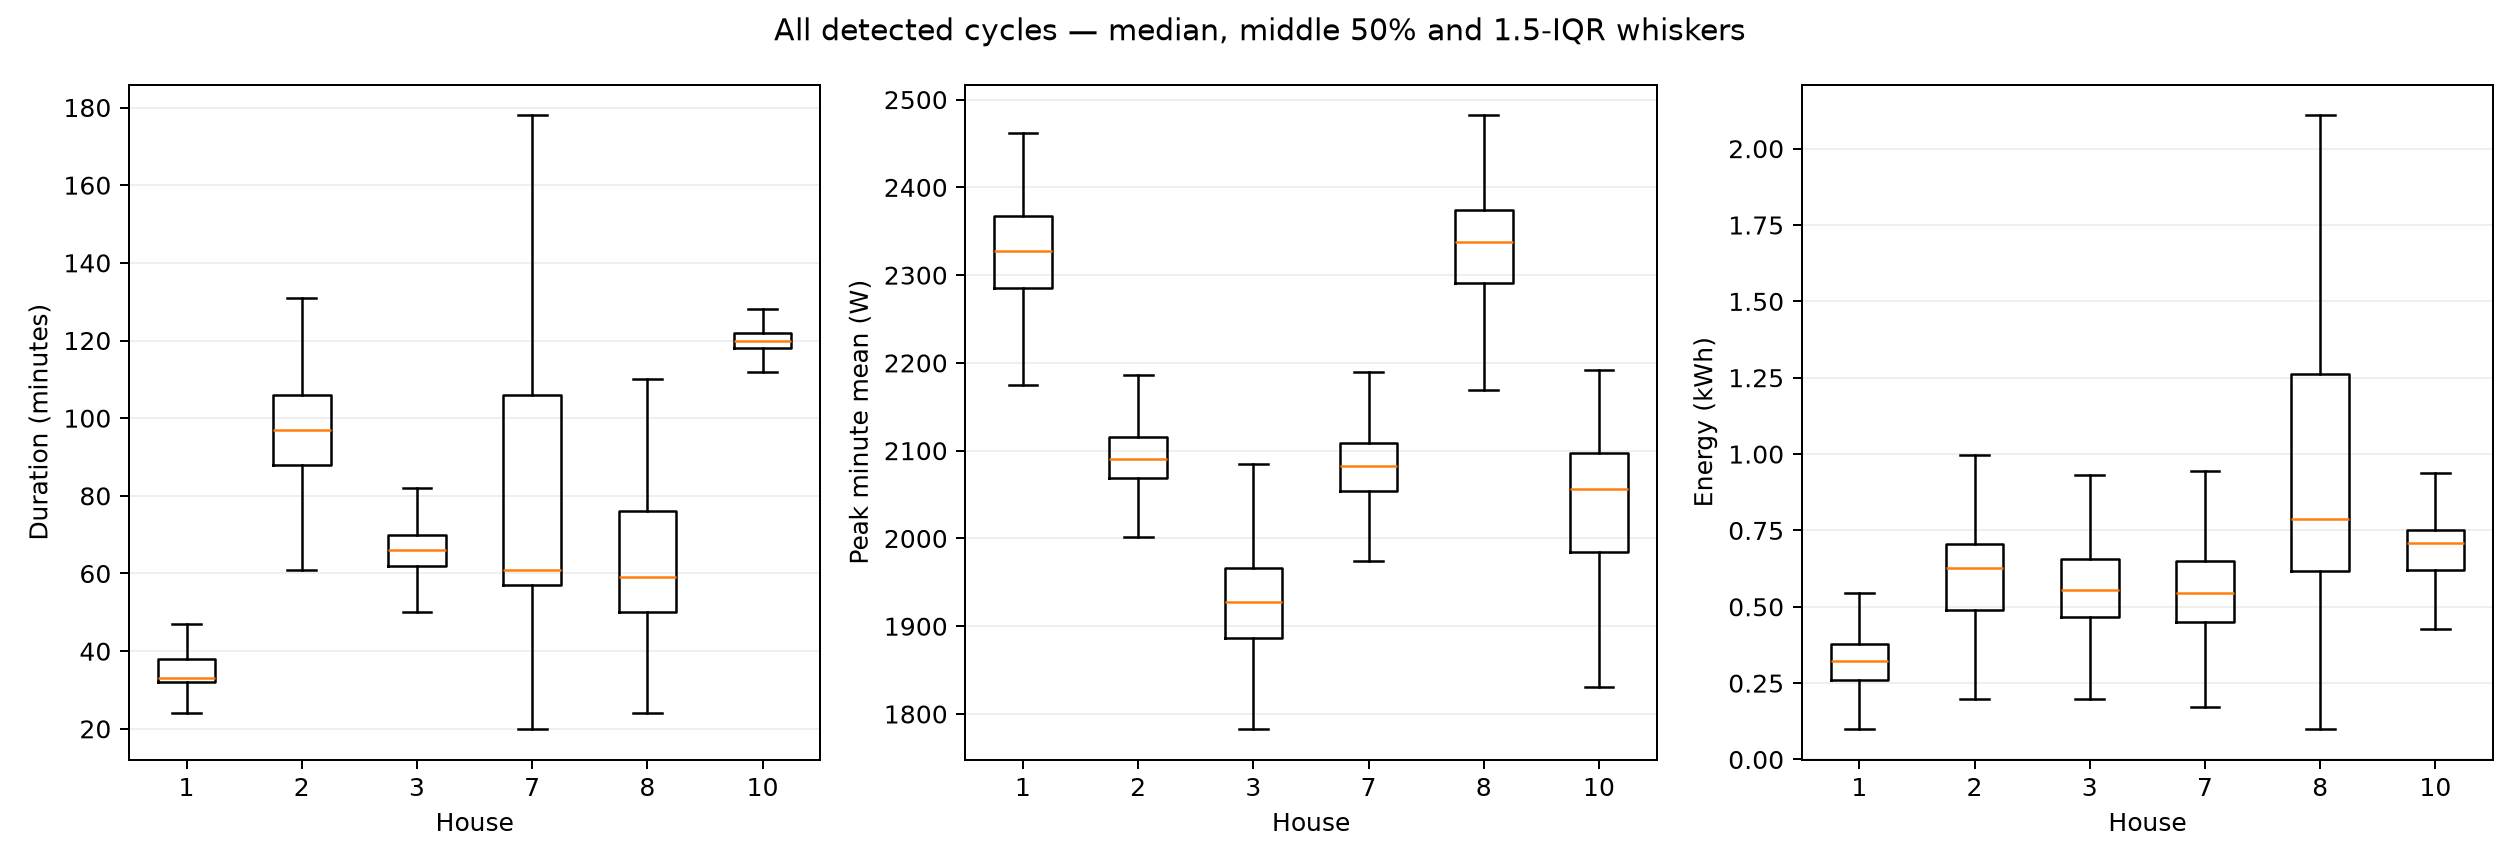

In [9]:
display(Image(filename=str(R/'eda/figures/cross_house_cycle_comparison.png')))

## Model evaluation
One model with twelve features, one validation-tuned probability threshold and a ten-minute run rule. Compare both named splits, classifier and non-ML baselines, and six-house LOHO; matched-cycle errors must be read with recall.

In [10]:
display(pd.read_csv(R/'model/evaluation_metrics.csv'))
display(pd.read_csv(R/'model/cycle_evaluation_metrics.csv'))
display(pd.read_csv(R/'model/loho_evaluation_metrics.csv'))
display(pd.read_csv(R/'model/loho_summary_metrics.csv'))

,fold,split,house,validation_house,training_houses,predictor,MAE_W,RMSE_W,active_MAE_W,inactive_MAE_W,precision_pct,recall_pct,F1_pct,true_energy_kwh,predicted_energy_kwh,SAE_pct
0,2,validation,1,1,"3,7,8,10",always_off,10.886611,137.989096,576.790207,0.033490,0.000000,0.000000,0.000000,145.839394,0.000000,100.000000
1,2,validation,1,1,"3,7,8,10",usage_profile,40.215286,140.200505,543.126480,30.570258,2.243607,79.292562,4.363741,145.839394,411.073251,181.867087
2,2,validation,1,1,"3,7,8,10",plain_classifier,14.062973,135.683081,544.085174,3.897999,14.995524,42.082645,22.111827,145.839394,60.669082,58.400073
3,2,validation,1,1,"3,7,8,10",two_stage_hgb,19.622954,154.963370,450.895878,11.351833,15.010616,42.069421,22.126402,145.839394,188.953657,29.562838
4,2,test,2,1,"3,7,8,10",always_off,18.090089,171.812575,384.139077,0.084636,0.000000,0.000000,0.000000,202.055446,0.000000,100.000000
5,2,test,2,1,"3,7,8,10",usage_profile,45.308215,171.522112,351.112023,30.266140,6.173932,87.701709,11.535781,202.055446,342.859448,69.685824
6,2,test,2,1,"3,7,8,10",plain_classifier,22.869613,167.793941,362.000906,6.188205,20.586423,36.156466,26.235263,202.055446,83.280956,58.783117
7,2,test,2,1,"3,7,8,10",two_stage_hgb,39.755113,220.346915,289.701822,27.460574,20.585405,36.083262,26.215141,202.055446,384.983226,90.533457
8,3,validation,8,8,"1,2,7,10",always_off,29.317560,243.515771,875.927737,0.216773,0.000000,0.000000,0.000000,350.452823,0.000000,100.000000
9,3,validation,8,8,"1,2,7,10",usage_profile,51.992851,243.695282,859.231580,24.245392,1.713920,27.884535,3.229349,350.452823,288.105130,17.790610


,fold,split,house,predictor,matching,true_cycles,predicted_cycles,matched_cycles,cycle_precision_pct,cycle_recall_pct,cycle_F1_pct,median_start_error_min,median_duration_error_min,median_energy_error_kwh,median_energy_error_pct
0,2,validation,1,plain_classifier,overlap_or_start_30min,367,125,23,18.400000,6.267030,9.349593,31.0,58.0,0.260916,67.997408
1,2,validation,1,plain_classifier,strict_start_10min,367,125,5,4.000000,1.362398,2.032520,4.0,36.0,0.471487,78.645358
2,2,validation,1,two_stage_hgb,overlap_or_start_30min,367,461,123,26.681128,33.514986,29.710145,3.0,15.0,0.188206,48.203161
3,2,validation,1,two_stage_hgb,strict_start_10min,367,461,80,17.353579,21.798365,19.323671,1.0,8.5,0.160903,45.537954
4,2,test,2,plain_classifier,overlap_or_start_30min,313,228,78,34.210526,24.920128,28.835490,12.5,30.0,0.494408,75.227437
5,2,test,2,plain_classifier,strict_start_10min,313,228,35,15.350877,11.182109,12.939002,6.0,26.0,0.556697,78.041965
6,2,test,2,two_stage_hgb,overlap_or_start_30min,313,589,156,26.485569,49.840256,34.589800,9.0,47.0,0.234246,39.455750
7,2,test,2,two_stage_hgb,strict_start_10min,313,589,84,14.261460,26.837061,18.625277,6.0,41.5,0.221966,35.597409
8,3,validation,8,plain_classifier,overlap_or_start_30min,367,78,59,75.641026,16.076294,26.516854,9.0,15.0,0.894787,89.523585
9,3,validation,8,plain_classifier,strict_start_10min,367,78,30,38.461538,8.174387,13.483146,4.5,14.0,0.857207,88.388829


,fold,split,house,validation_house,training_houses,predictor,MAE_W,RMSE_W,active_MAE_W,inactive_MAE_W,precision_pct,recall_pct,F1_pct,true_energy_kwh,predicted_energy_kwh,SAE_pct,cycle_precision_pct,cycle_recall_pct,cycle_F1_pct,median_start_error_min,median_duration_error_min,median_energy_error_kwh
0,1,test,1,2,"3,7,8,10",always_off,10.886611,137.989096,576.790207,0.033490,0.000000,0.000000,0.000000,145.839394,0.000000,100.000000,NaN,NaN,NaN,NaN,NaN,NaN
1,1,test,1,2,"3,7,8,10",usage_profile,40.215286,140.200505,543.126480,30.570258,2.243607,79.292562,4.363741,145.839394,411.073251,181.867087,NaN,NaN,NaN,NaN,NaN,NaN
2,1,test,1,2,"3,7,8,10",plain_classifier,19.977685,134.811473,515.093199,10.482166,9.324522,88.621488,16.873643,145.839394,155.566957,6.670052,NaN,NaN,NaN,NaN,NaN,NaN
3,1,test,1,2,"3,7,8,10",two_stage_hgb,30.379271,168.008605,371.635541,23.834525,10.120351,86.175207,18.113470,145.839394,376.462800,158.135192,29.497908,76.839237,42.630385,1.0,24.0,0.149018
4,2,test,2,1,"3,7,8,10",always_off,18.090089,171.812575,384.139077,0.084636,0.000000,0.000000,0.000000,202.055446,0.000000,100.000000,NaN,NaN,NaN,NaN,NaN,NaN
5,2,test,2,1,"3,7,8,10",usage_profile,45.308215,171.522112,351.112023,30.266140,6.173932,87.701709,11.535781,202.055446,342.859448,69.685824,NaN,NaN,NaN,NaN,NaN,NaN
6,2,test,2,1,"3,7,8,10",plain_classifier,22.869613,167.793941,362.000906,6.188205,20.586423,36.156466,26.235263,202.055446,83.280956,58.783117,NaN,NaN,NaN,NaN,NaN,NaN
7,2,test,2,1,"3,7,8,10",two_stage_hgb,39.755113,220.346915,289.701822,27.460574,20.585405,36.083262,26.215141,202.055446,384.983226,90.533457,26.485569,49.840256,34.589800,9.0,47.0,0.234246
8,3,test,3,8,"1,2,7,10",always_off,28.649014,207.630421,505.479691,0.033104,0.000000,0.000000,0.000000,374.539067,0.000000,100.000000,NaN,NaN,NaN,NaN,NaN,NaN
9,3,test,3,8,"1,2,7,10",usage_profile,48.610274,204.716350,470.020769,23.320280,9.227474,88.081245,16.704924,374.539067,315.124626,15.863349,NaN,NaN,NaN,NaN,NaN,NaN


,predictor,metric,mean,SD,median,Q1,Q3
0,always_off,MAE_W,26.225548,9.935534e+00,28.983287,20.729821,31.651277
1,always_off,RMSE_W,204.016743,4.242858e+01,211.604357,180.767036,236.531402
2,always_off,active_MAE_W,527.546482,1.871605e+02,478.942275,401.205522,558.962578
3,always_off,F1_pct,0.000000,0.000000e+00,0.000000,0.000000,0.000000
4,always_off,SAE_pct,100.000000,6.355287e-15,100.000000,100.000000,100.000000
5,always_off,cycle_F1_pct,NaN,NaN,NaN,NaN,NaN
6,always_off,median_start_error_min,NaN,NaN,NaN,NaN,NaN
7,plain_classifier,MAE_W,31.030038,8.619464e+00,32.504616,25.184525,34.000551
8,plain_classifier,RMSE_W,197.904682,4.028770e+01,205.161733,176.226922,229.862175
9,plain_classifier,active_MAE_W,480.400610,1.777647e+02,427.790605,369.825787,501.890094


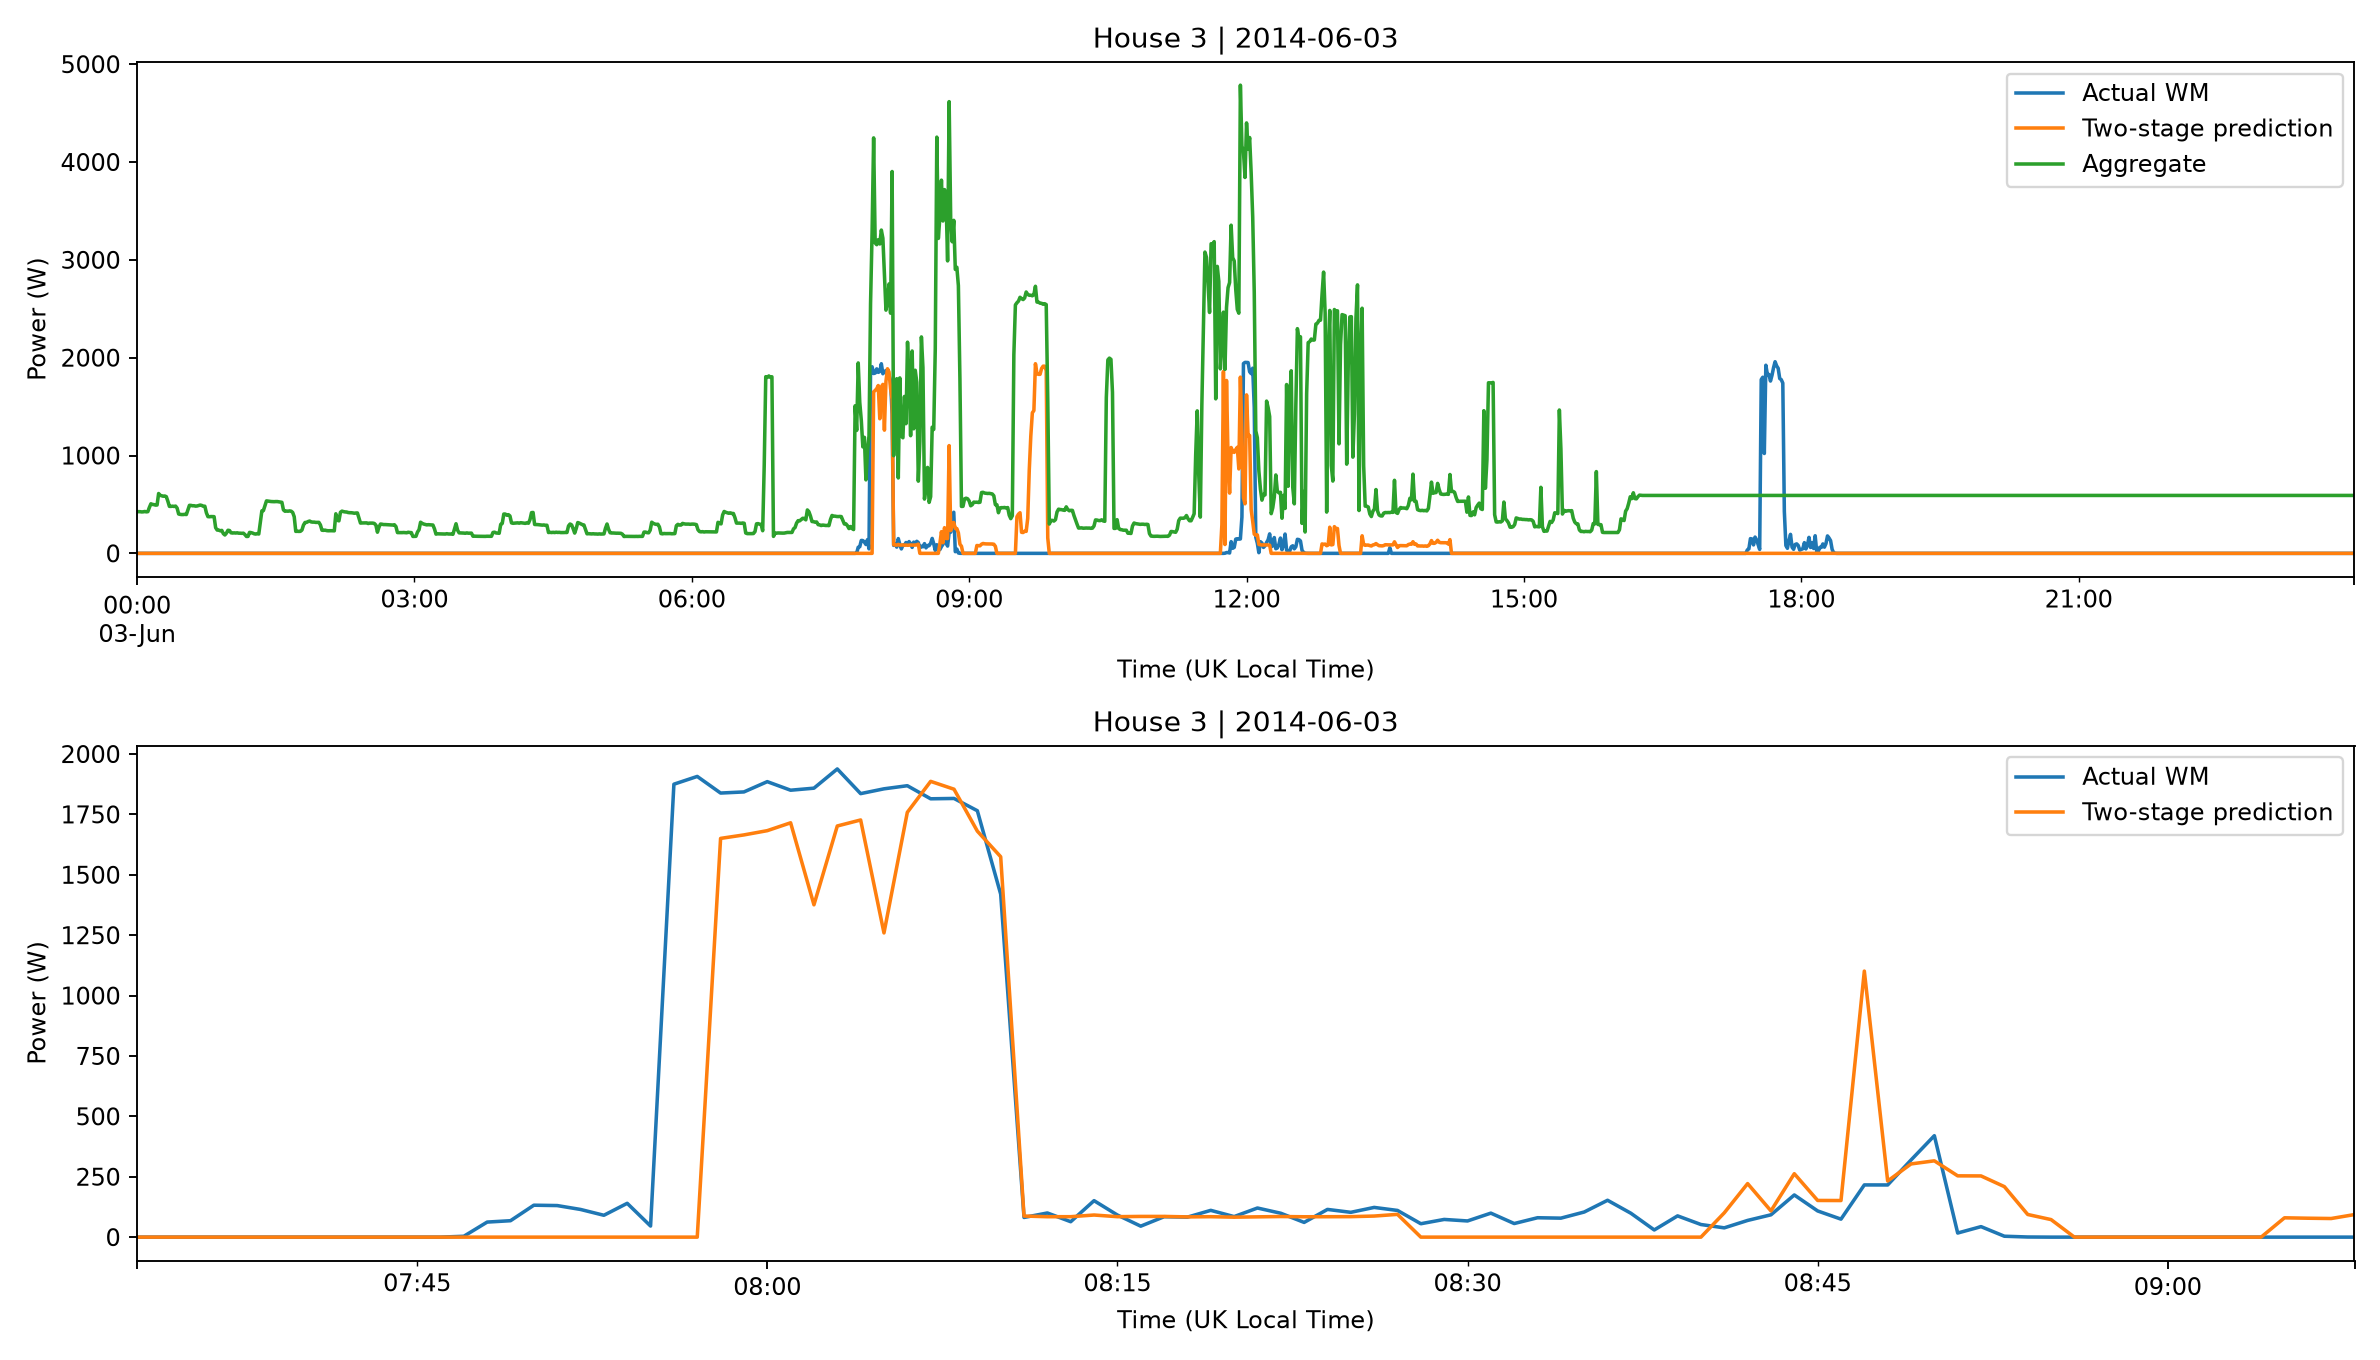

In [11]:
display(Image(filename=str(R/'model/test_actual_vs_predicted.png')))

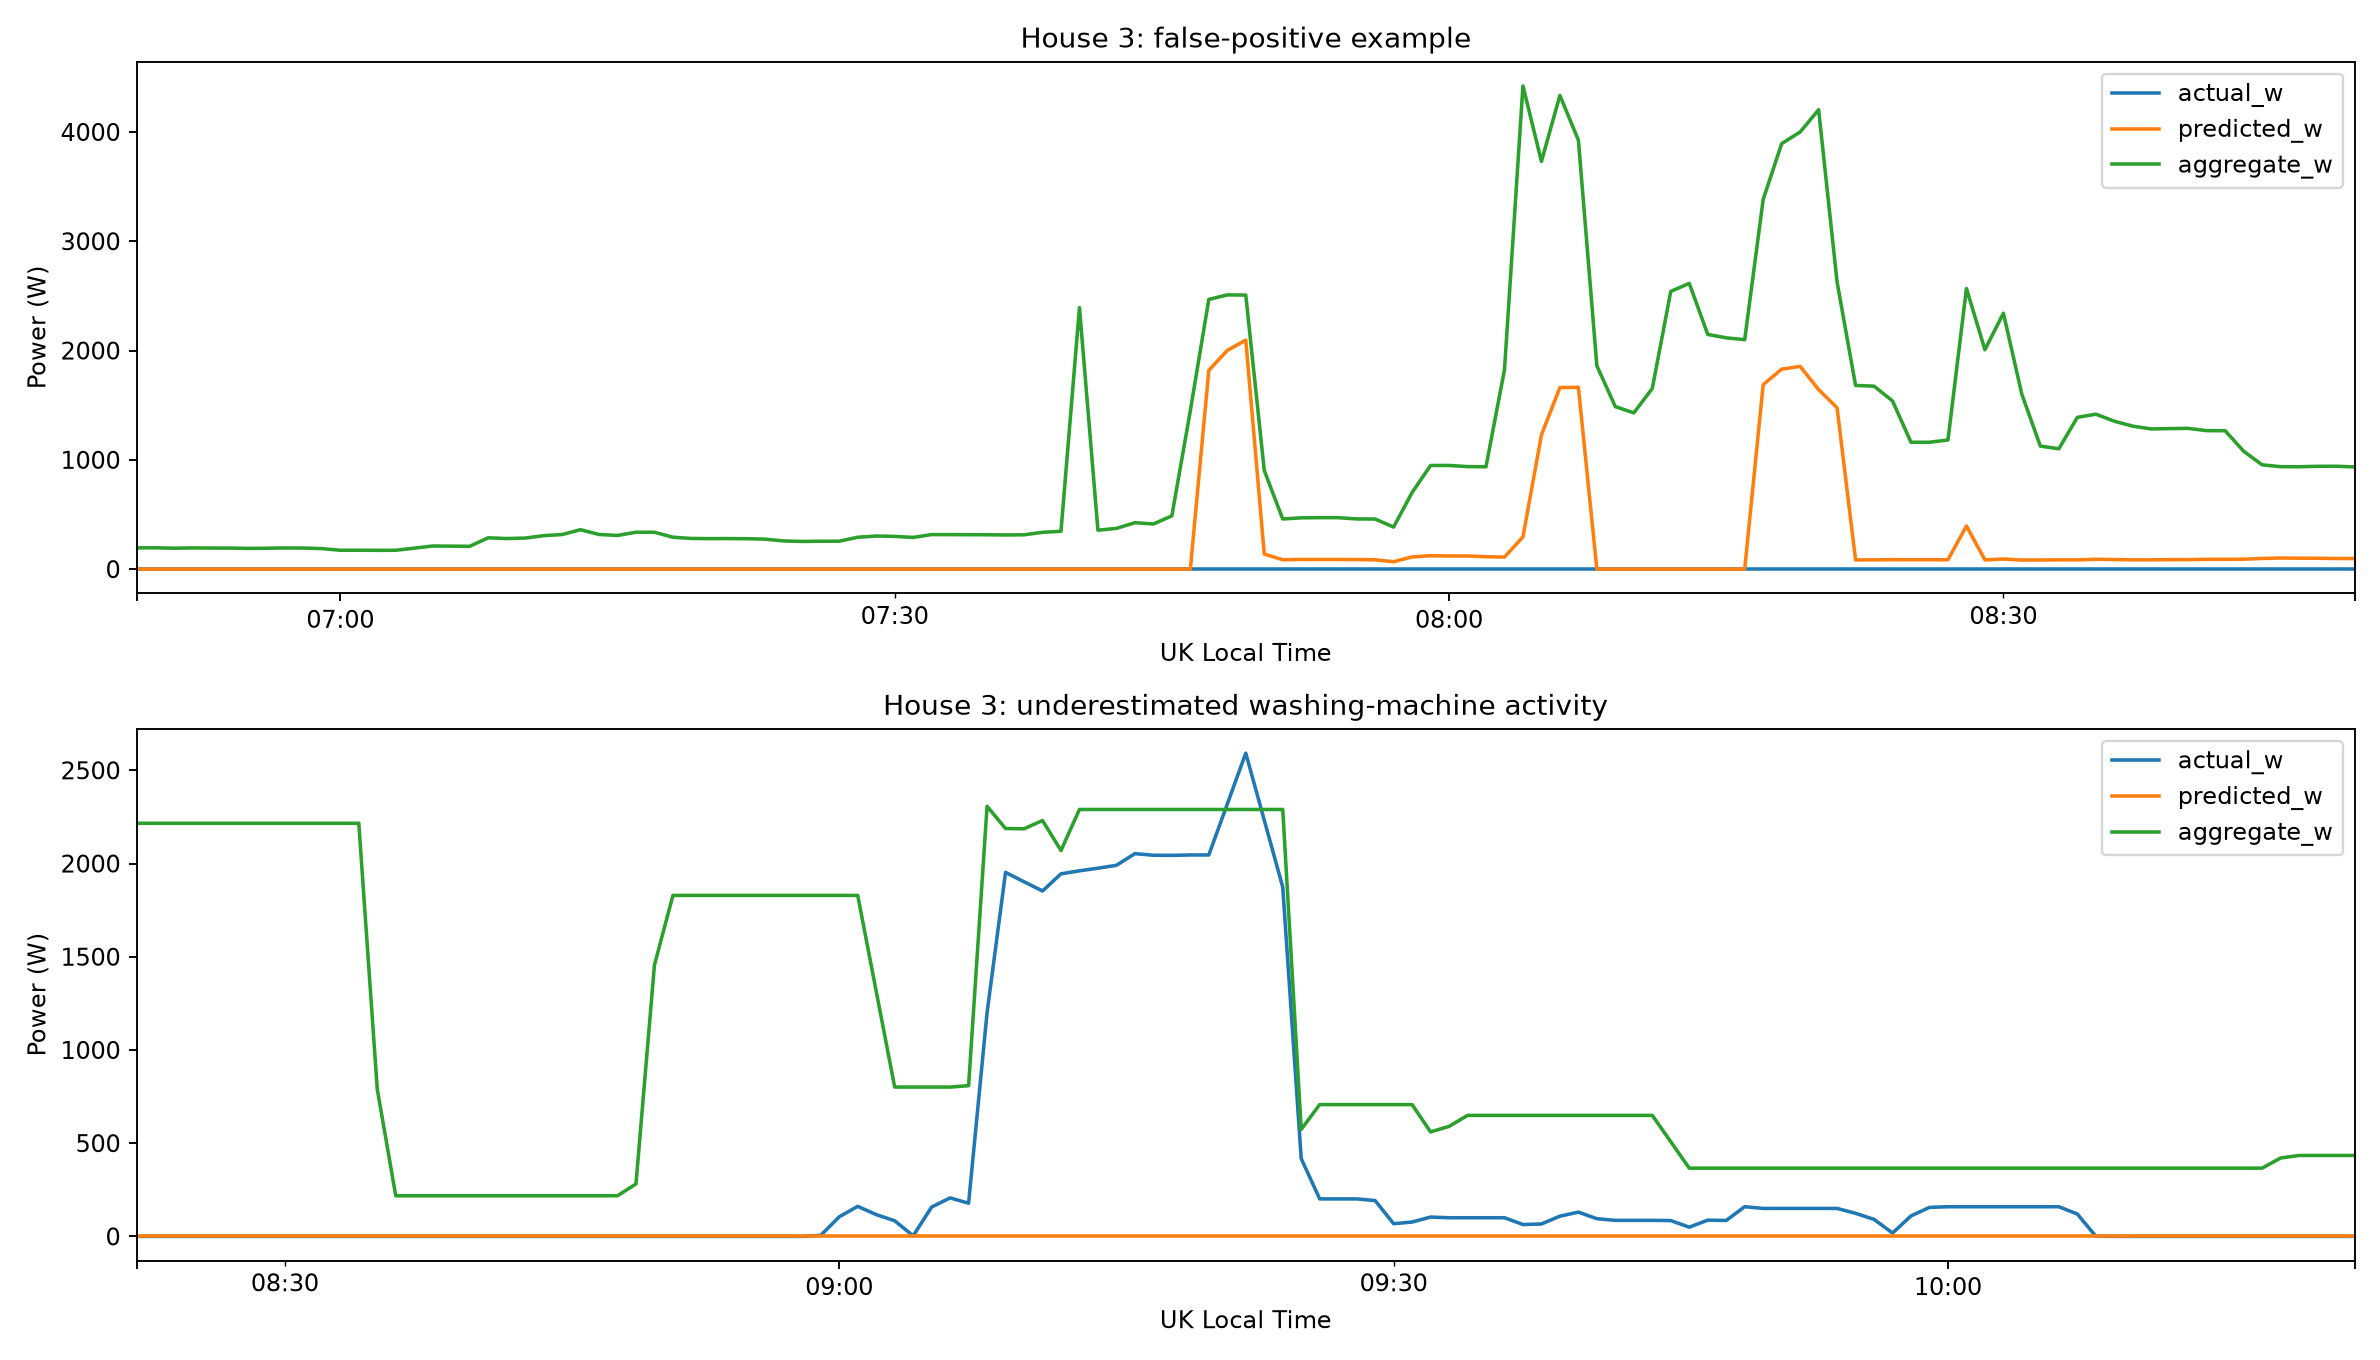

In [12]:
display(Image(filename=str(R/'model/failure_cases_examples.png')))

Illustrative day: 2014-06-03, UK local time. It has 1,440 observed minutes and is selected nearest median daily cycle F1. See Recommendation.md for a measured utility pilot and transfer limits.

In [13]:
display(pd.read_csv(R/'model/test_false_alarm_appliance_evidence.csv'))

,channel,appliance,mean_W_at_false_alarm
0,Appliance9,Kettle,1862.4
1,Appliance3,Freezer,88.7
2,Appliance2,Fridge-Freezer,83.6
3,Appliance1,Toaster,0.0
4,Appliance4,Tumble Dryer,0.0
5,Appliance5,Dishwasher,0.0
6,Appliance6,Washing Machine,0.0
7,Appliance7,Television Site,0.0
8,Appliance8,Microwave,0.0
